In [57]:
# Import the Required Libraries

# ==========================================
# Predictive Analytics for Airline Flight Delays
# Phase 4: Predictive Modeling
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [58]:
# Load the Cleaned Dataset
# Define project directory

project_root = Path(r"C:\Repo\airline-flights")

# Define processed dataset location

data_file = (
    project_root
    / "data"
    / "processed"
    / "flights_2025_cleaned.parquet"
)

# Load the dataset

df = pd.read_parquet(data_file)

print("Dataset loaded successfully.")

print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (6879483, 30)


,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,...,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,ARR_DEL15_TARGET,FLIGHT_MONTH,FLIGHT_DAY,FLIGHT_WEEKDAY,DEP_HOUR
0,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,500,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,5.0
1,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,555,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,5.0
2,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,820,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,8.0
3,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,1032,...,NaN,NaN,NaN,NaN,NaN,0,1,1,2,10.0
4,2025,1,1,1,3,2025-01-01,AA,ABQ,DFW,1700,...,7.0,0.0,10.0,0.0,0.0,1,1,1,2,17.0


Validate the Dataset Before Modeling

In [59]:
# Verify the Required Attributes
# Required attributes

required_columns = [
    "FL_DATE",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "DISTANCE",
    "CRS_ARR_TIME",
    "FLIGHT_MONTH",
    "FLIGHT_WEEKDAY",
    "DEP_HOUR",
    "ARR_DEL15_TARGET"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required attributes are available.")

print("\nTarget distribution:")
print(
    df["ARR_DEL15_TARGET"]
    .value_counts(dropna=False)
)

All required attributes are available.

Target distribution:
ARR_DEL15_TARGET
0    5344845
1    1534638
Name: count, dtype: int64


In [60]:
# Validate the Target
# Check target values

print("Missing target values:")
print(df["ARR_DEL15_TARGET"].isna().sum())

print("\nUnique target values:")
print(df["ARR_DEL15_TARGET"].unique())

assert df["ARR_DEL15_TARGET"].notna().all()

assert set(
    df["ARR_DEL15_TARGET"].unique()
).issubset({0, 1})

print("\nTarget validation successful.")

Missing target values:


0

Unique target values:
[0 1]

Target validation successful.


Feature Engineering for Prediction

In [61]:
# Create scheduled arrival hour

df["ARR_HOUR"] = (
    pd.to_numeric(
        df["CRS_ARR_TIME"],
        errors="coerce"
    ) // 100
)

# Convert 2400 to midnight

df["ARR_HOUR"] = (
    df["ARR_HOUR"].replace(24, 0)
)

# Handle invalid hour values

df.loc[
    ~df["ARR_HOUR"].between(0, 23),
    "ARR_HOUR"
] = np.nan

# Review new feature

display(
    df[
        [
            "CRS_ARR_TIME",
            "ARR_HOUR",
            "DEP_HOUR",
            "ARR_DEL15_TARGET"
        ]
    ].head()
)

,CRS_ARR_TIME,ARR_HOUR,DEP_HOUR,ARR_DEL15_TARGET
0,754,7.0,5.0,0
1,849,8.0,5.0,0
2,1114,11.0,8.0,0
3,1323,13.0,10.0,0
4,1948,19.0,17.0,1


Define the Independent and Dependent Variables

In [62]:
# Select Modeling Features
# Define categorical variables

categorical_features = [
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST"
]

# Define numerical variables

numerical_features = [
    "DISTANCE",
    "FLIGHT_MONTH",
    "FLIGHT_WEEKDAY",
    "DEP_HOUR",
    "ARR_HOUR"
]

# Combine feature names

feature_columns = (
    categorical_features
    + numerical_features
)

# Create independent variables

X = df[feature_columns].copy()

# Create dependent variable

y = df["ARR_DEL15_TARGET"].astype(int)

print("Independent variables:", X.shape)

print("Dependent variable:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

Independent variables: (6879483, 8)
Dependent variable: (6879483,)

Selected features:
['OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'DISTANCE', 'FLIGHT_MONTH', 'FLIGHT_WEEKDAY', 'DEP_HOUR', 'ARR_HOUR']


Split the Data Chronologically

In [63]:
# Prepare the Chronological Split
# Convert flight dates

df["FL_DATE"] = pd.to_datetime(
    df["FL_DATE"],
    errors="coerce"
)

# Define split boundaries

train_mask = (
    df["FL_DATE"] < "2025-10-01"
)

validation_mask = (
    (df["FL_DATE"] >= "2025-10-01")
    & (df["FL_DATE"] < "2025-12-01")
)

test_mask = (
    df["FL_DATE"] >= "2025-12-01"
) & (
    df["FL_DATE"] < "2026-01-01"
)

# Create training data

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

# Create validation data

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

# Create testing data

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print(
    "\nTotal records:",
    len(X_train) + len(X_val) + len(X_test)
)

# Verify the split

assert (
    len(X_train)
    + len(X_val)
    + len(X_test)
) == len(df)

assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

print("Chronological data split verified.")

Training records: 5150694
Validation records: 1156865
Testing records: 571924

Total records: 6879483
Chronological data split verified.


Build the Preprocessing Pipeline

In [64]:
# Create the Preprocessing Pipeline
# Numerical preprocessing

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


Establish a Baseline Model

In [65]:
# Train a Baseline Classifier
# Create baseline model

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline

baseline_model.fit(
    X_train,
    y_train
)

# Predict validation outcomes

baseline_predictions = (
    baseline_model.predict(X_val)
)

# Evaluate baseline

baseline_accuracy = accuracy_score(
    y_val,
    baseline_predictions
)

baseline_precision = precision_score(
    y_val,
    baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    y_val,
    baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    y_val,
    baseline_predictions,
    zero_division=0
)

print("Baseline Model Performance")
print("--------------------------")

print(
    f"Accuracy: {baseline_accuracy:.4f}"
)

print(
    f"Precision: {baseline_precision:.4f}"
)

print(
    f"Recall: {baseline_recall:.4f}"
)

print(
    f"F1-Score: {baseline_f1:.4f}"
)

Baseline Model Performance
--------------------------
Accuracy: 0.7956
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000


Prepare to Train Logistic Regression

In [66]:
# Create a Development Sample
# Create a reproducible development sample

sample_size = min(
    300_000,
    len(X_train)
)

sample_indices, _ = train_test_split(
    np.arange(len(X_train)),
    train_size=sample_size,
    random_state=42,
    stratify=y_train
)

X_train_sample = X_train.iloc[
    sample_indices
].copy()

y_train_sample = y_train.iloc[
    sample_indices
].copy()

print(
    "Development sample size:",
    len(X_train_sample)
)

print("\nSample target distribution:")
print(
    y_train_sample.value_counts(
        normalize=True
    ).round(4)
)

Development sample size: 300000

Sample target distribution:
ARR_DEL15_TARGET
0    0.7777
1    0.2223
Name: proportion, dtype: float64


Train Logistic Regression

In [67]:
# Create and Train the Model
# Build Logistic Regression pipeline

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                solver="lbfgs"
            )
        )
    ]
)

# Train model

logistic_model.fit(
    X_train_sample,
    y_train_sample
)

print(
    "Logistic Regression training completed."
)

Logistic Regression training completed.


Evaluate Logistic Regression

In [68]:
# Generate Validation Predictions
# Generate predictions

logistic_predictions = (
    logistic_model.predict(X_val)
)

# Generate predicted probabilities

logistic_probabilities = (
    logistic_model.predict_proba(X_val)[:, 1]
)

In [69]:
# Calculate Performance Metrics
# Evaluate Logistic Regression

logistic_results = {
    "Model": "Logistic Regression",

    "Accuracy": accuracy_score(
        y_val,
        logistic_predictions
    ),

    "Precision": precision_score(
        y_val,
        logistic_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_val,
        logistic_predictions,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_val,
        logistic_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_val,
        logistic_probabilities
    )
}

display(
    pd.DataFrame([logistic_results])
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.792398,0.368904,0.022299,0.042056,0.63711


Create a Confusion Matrix

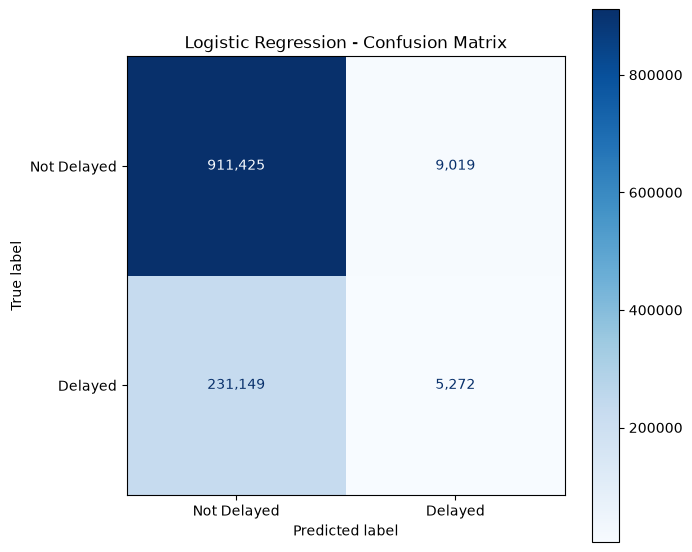

In [70]:
# Generate confusion matrix

cm = confusion_matrix(
    y_val,
    logistic_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Delayed",
        "Delayed"
    ]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d"
)

plt.title(
    "Logistic Regression - Confusion Matrix"
)

plt.tight_layout()

# Save visualization

figures_path = (
    project_root
    / "reports"
    / "figures"
)

figures_path.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figures_path
    / "06_logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
# ==========================================
# Logistic Regression Threshold Evaluation
# ==========================================

thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_val,
            predictions
        ),

        "Precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_val,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.20,0.4973,0.2554,0.7619,0.3825
1,0.25,0.6031,0.2797,0.5980,0.3812
2,0.30,0.6804,0.3024,0.4315,0.3556
3,0.35,0.7334,0.3206,0.2722,0.2944
4,0.40,0.7665,0.3382,0.1490,0.2069
5,0.45,0.7847,0.3563,0.0661,0.1116
6,0.50,0.7924,0.3689,0.0223,0.0421


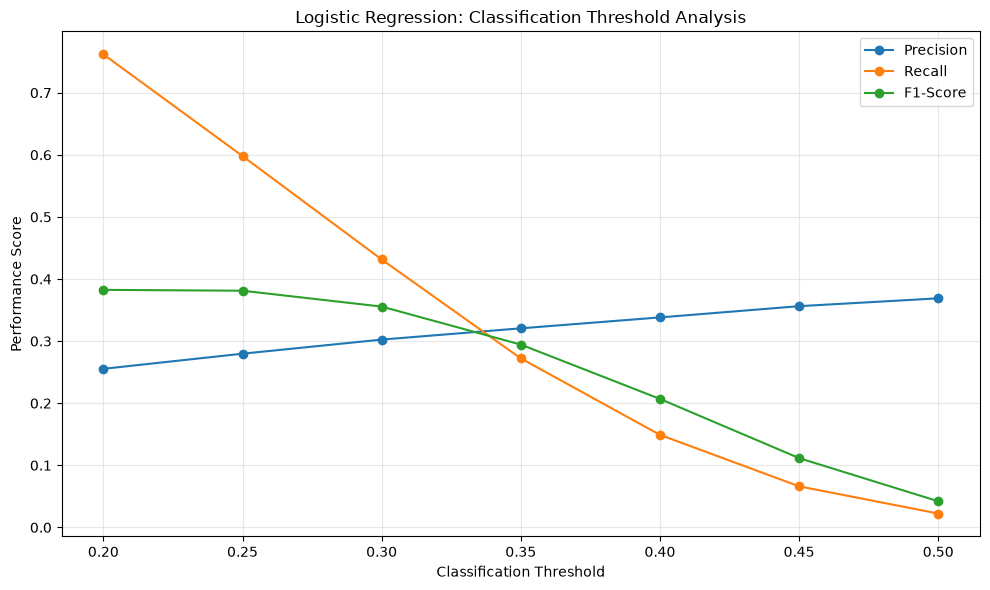

In [72]:
# Visualize threshold performance

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title(
    "Logistic Regression: Classification Threshold Analysis"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Performance Score")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_path /
    "07_logistic_regression_threshold_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [73]:
# Recommended Improvement: Evaluate Class Weighting

class_weight="balanced"

In [74]:
# Train a Class-Weighted Logistic Regression Model

from sklearn.base import clone

# Create a new preprocessing pipeline
# and Logistic Regression classifier

balanced_logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                solver="lbfgs",
                class_weight="balanced"
            )
        )
    ]
)

# Train using development sample

balanced_logistic_model.fit(
    X_train_sample,
    y_train_sample
)

# Predict validation outcomes

balanced_predictions = (
    balanced_logistic_model.predict(X_val)
)

balanced_probabilities = (
    balanced_logistic_model.predict_proba(
        X_val
    )[:, 1]
)

# Evaluate

balanced_results = {
    "Model": "Balanced Logistic Regression",

    "Accuracy": accuracy_score(
        y_val,
        balanced_predictions
    ),

    "Precision": precision_score(
        y_val,
        balanced_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_val,
        balanced_predictions,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_val,
        balanced_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_val,
        balanced_probabilities
    )
}

display(
    pd.DataFrame([
        logistic_results,
        balanced_results
    ]).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7924,0.3689,0.0223,0.0421,0.6371
1,Balanced Logistic Regression,0.5607,0.2694,0.6713,0.3845,0.6370


In [75]:
# One Additional Recommendation: Add PR-AUC

from sklearn.metrics import average_precision_score

print(
    "Logistic Regression Average Precision:",
    round(
        average_precision_score(
            y_val,
            logistic_probabilities
        ),
        4
    )
)

print(
    "Balanced Logistic Regression Average Precision:",
    round(
        average_precision_score(
            y_val,
            balanced_probabilities
        ),
        4
    )
)

Logistic Regression Average Precision: 0.2907
Balanced Logistic Regression Average Precision: 0.2897


Interpretation

The baseline predicts that every flight will be not delayed.

Because approximately 79.56% of the validation flights were not delayed, this strategy achieves relatively high accuracy.

However, it completely fails to identify delayed flights.

That is why precision, recall, and F1-score are all zero.

This baseline establishes an important comparison point: Our machine learning models should ideally identify delayed flights while maintaining a reasonable balance between missed delays and false alarms.

Balanced Logistic Regression Results

In [76]:
class_weight="balanced"

In [77]:
# Develop a Decision Tree Classifier
# ==========================================
# Decision Tree Classifier
# ==========================================

from sklearn.base import clone

decision_tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=12,
                min_samples_leaf=100,
                random_state=42
            )
        )
    ]
)

# Train Decision Tree model
decision_tree_model.fit(
    X_train_sample,
    y_train_sample
)

print("Decision Tree training completed.")

Decision Tree training completed.


In [78]:
# Evaluate the Decision Tree
# Generate validation predictions

tree_predictions = (
    decision_tree_model.predict(X_val)
)

tree_probabilities = (
    decision_tree_model.predict_proba(X_val)[:, 1]
)

# Evaluate Decision Tree

tree_results = {
    "Model": "Decision Tree",

    "Accuracy": accuracy_score(
        y_val,
        tree_predictions
    ),

    "Precision": precision_score(
        y_val,
        tree_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_val,
        tree_predictions,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_val,
        tree_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_val,
        tree_probabilities
    )
}

display(
    pd.DataFrame([
        logistic_results,
        balanced_results,
        tree_results
    ]).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7924,0.3689,0.0223,0.0421,0.6371
1,Balanced Logistic Regression,0.5607,0.2694,0.6713,0.3845,0.6370
2,Decision Tree,0.7949,0.3845,0.0058,0.0115,0.6249


Evaluate Decision Tree Average Precision

In [79]:
from sklearn.metrics import average_precision_score

tree_average_precision = (
    average_precision_score(
        y_val,
        tree_probabilities
    )
)

print(
    "Decision Tree Average Precision:",
    round(tree_average_precision, 4)
)

Decision Tree Average Precision: 0.2826


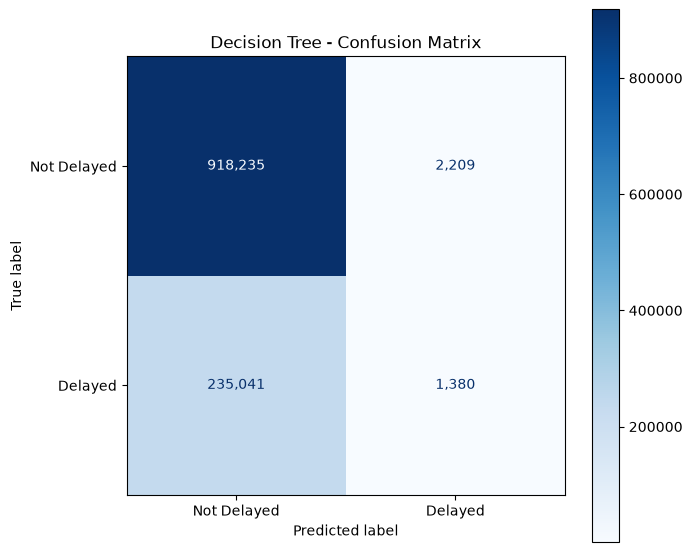

In [80]:
# Decision Tree confusion matrix

tree_cm = confusion_matrix(
    y_val,
    tree_predictions
)

tree_display = ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=[
        "Not Delayed",
        "Delayed"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

tree_display.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d"
)

plt.title("Decision Tree - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    figures_path /
    "08_decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Random Forest Classifier

This section develops a Random Forest classification model
to predict airline arrival delays of 15 minutes or more.

The model uses the same training sample, predictors,
and chronological validation dataset as the previous models.

In [81]:
# Train the Random Forest
# ==========================================
# Random Forest Classifier
# ==========================================

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=100,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the Random Forest model
random_forest_model.fit(
    X_train_sample,
    y_train_sample
)

print("Random Forest training completed.")

Random Forest training completed.


Evaluate Random Forest Performance

In [82]:
# Random Forest validation predictions

rf_predictions = random_forest_model.predict(X_val)

rf_probabilities = (
    random_forest_model.predict_proba(X_val)[:, 1]
)

print("Random Forest predictions completed.")

Random Forest predictions completed.


In [83]:
# Calculate Evaluation Metrics
# ==========================================
# Random Forest Evaluation
# ==========================================

from sklearn.metrics import average_precision_score

rf_results = {
    "Model": "Random Forest",

    "Accuracy": accuracy_score(
        y_val,
        rf_predictions
    ),

    "Precision": precision_score(
        y_val,
        rf_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_val,
        rf_predictions,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_val,
        rf_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_val,
        rf_probabilities
    )
}

rf_average_precision = average_precision_score(
    y_val,
    rf_probabilities
)

print(
    "Random Forest Average Precision:",
    round(rf_average_precision, 4)
)

display(
    pd.DataFrame([rf_results]).round(4)
)

Random Forest Average Precision: 0.2943


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7956,0.0,0.0,0.0,0.6359


Generate the Random Forest Confusion Matrix

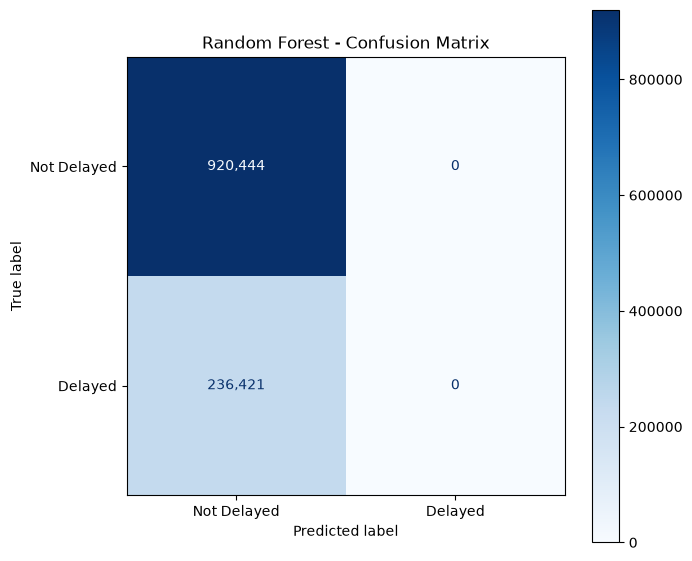

In [84]:
# Create and Save the Visualization
# ==========================================
# Random Forest Confusion Matrix
# ==========================================

rf_cm = confusion_matrix(
    y_val,
    rf_predictions
)

rf_display = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=[
        "Not Delayed",
        "Delayed"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

rf_display.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d"
)

plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()

figures_path = (
    project_root /
    "reports" /
    "figures"
)

figures_path.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figures_path /
    "09_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare All Four Models

In [85]:
# Create a Model Comparison Table
# ==========================================
# Model Comparison
# ==========================================

model_comparison = pd.DataFrame([
    logistic_results,
    balanced_results,
    tree_results,
    rf_results
])

# Add Average Precision
model_comparison["Average Precision"] = [
    average_precision_score(
        y_val, logistic_probabilities
    ),
    average_precision_score(
        y_val, balanced_probabilities
    ),
    tree_average_precision,
    rf_average_precision
]

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.7924,0.3689,0.0223,0.0421,0.6371,0.2907
1,Balanced Logistic Regression,0.5607,0.2694,0.6713,0.3845,0.6370,0.2897
2,Decision Tree,0.7949,0.3845,0.0058,0.0115,0.6249,0.2826
3,Random Forest,0.7956,0.0000,0.0000,0.0000,0.6359,0.2943


Evaluate Alternative Thresholds for Decision Tree and Random Forest

In [86]:
# Create a Reusable Threshold Evaluation Function
# ==========================================
# Reusable Threshold Evaluation Function
# ==========================================

def evaluate_thresholds(
    y_true,
    probabilities,
    model_name,
    thresholds=np.arange(0.10, 0.51, 0.05)
):

    results = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        results.append({
            "Model": model_name,
            "Threshold": round(float(threshold), 2),

            "Accuracy": accuracy_score(
                y_true,
                predictions
            ),

            "Precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "Recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

            "F1-Score": f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        })

    return pd.DataFrame(results)

In [87]:
# Evaluate the Models
# Decision Tree thresholds

tree_threshold_results = evaluate_thresholds(
    y_val,
    tree_probabilities,
    "Decision Tree"
)

# Random Forest thresholds

rf_threshold_results = evaluate_thresholds(
    y_val,
    rf_probabilities,
    "Random Forest"
)

display(
    tree_threshold_results.round(4)
)

display(
    rf_threshold_results.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.10,0.4297,0.2398,0.8255,0.3717
1,Decision Tree,0.15,0.5792,0.2685,0.6140,0.3736
2,Decision Tree,0.20,0.6501,0.2931,0.5042,0.3707
3,Decision Tree,0.25,0.7266,0.3112,0.2784,0.2939
4,Decision Tree,0.30,0.7612,0.3243,0.1555,0.2102
5,Decision Tree,0.35,0.7657,0.3324,0.1455,0.2025
6,Decision Tree,0.40,0.7889,0.3852,0.0549,0.0961
7,Decision Tree,0.45,0.7914,0.3684,0.0291,0.0539
8,Decision Tree,0.50,0.7949,0.3845,0.0058,0.0115


,Model,Threshold,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.10,0.2044,0.2044,1.0000,0.3394
1,Random Forest,0.15,0.2258,0.2076,0.9903,0.3433
2,Random Forest,0.20,0.5351,0.2625,0.7046,0.3825
3,Random Forest,0.25,0.6489,0.2947,0.5154,0.3750
4,Random Forest,0.30,0.7876,0.3652,0.0530,0.0925
5,Random Forest,0.35,0.7956,0.0000,0.0000,0.0000
6,Random Forest,0.40,0.7956,0.0000,0.0000,0.0000
7,Random Forest,0.45,0.7956,0.0000,0.0000,0.0000
8,Random Forest,0.50,0.7956,0.0000,0.0000,0.0000


Identify the Best Validation Threshold

In [88]:
# Select the Best Threshold for Each Tree-Based Model
# Best Decision Tree threshold

best_tree = tree_threshold_results.loc[
    tree_threshold_results["F1-Score"].idxmax()
]

# Best Random Forest threshold

best_rf = rf_threshold_results.loc[
    rf_threshold_results["F1-Score"].idxmax()
]

print("Best Decision Tree threshold:")
display(best_tree.to_frame().T)

print("\nBest Random Forest threshold:")
display(best_rf.to_frame().T)

Best Decision Tree threshold:


,Model,Threshold,Accuracy,Precision,Recall,F1-Score
1,Decision Tree,0.15,0.5792,0.26847,0.614023,0.373593



Best Random Forest threshold:


,Model,Threshold,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.2,0.535113,0.262525,0.704641,0.382532


Visualize the Model Comparison

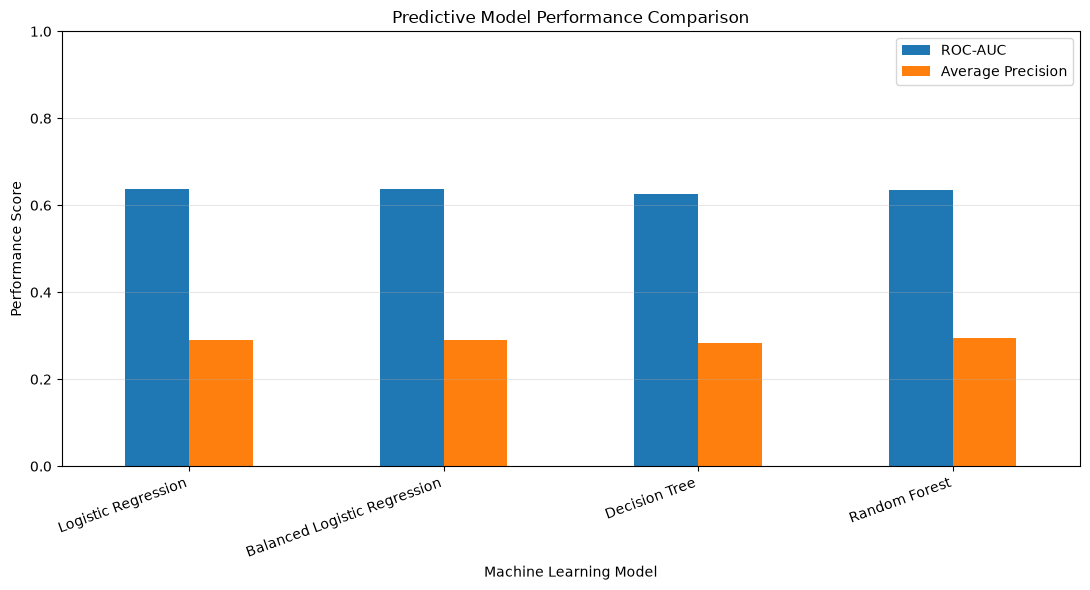

In [89]:
# Create and Save the Comparison Chart
# ==========================================
# Model Comparison Visualization
# ==========================================

comparison_plot = model_comparison.set_index("Model")[
    ["ROC-AUC", "Average Precision"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Predictive Model Performance Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Performance Score")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_path /
    "10_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Optimize Thresholds for All Four Models

In [90]:
# Evaluate All Models Using the Same Threshold Range
# ==========================================
# Compare Thresholds Across All Models
# ==========================================

models_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Balanced Logistic Regression": balanced_probabilities,
    "Decision Tree": tree_probabilities,
    "Random Forest": rf_probabilities
}

all_threshold_results = []

threshold_range = np.arange(0.10, 0.71, 0.025)

for model_name, probabilities in models_probabilities.items():

    results = evaluate_thresholds(
        y_val,
        probabilities,
        model_name,
        thresholds=threshold_range
    )

    all_threshold_results.append(results)

all_threshold_df = pd.concat(
    all_threshold_results,
    ignore_index=True
)

display(all_threshold_df.head())

,Model,Threshold,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.10,0.237373,0.209489,0.984925,0.345493
1,Logistic Regression,0.12,0.292548,0.218153,0.952707,0.355014
2,Logistic Regression,0.15,0.362372,0.229667,0.900576,0.365997
3,Logistic Regression,0.17,0.432456,0.242290,0.835400,0.375635
4,Logistic Regression,0.20,0.497323,0.255374,0.761929,0.382535


In [91]:
# ==========================================
# Identify Best Threshold for Each Model
# ==========================================

best_thresholds = (
    all_threshold_df
    .loc[
        all_threshold_df
        .groupby("Model")["F1-Score"]
        .idxmax()
    ]
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    best_thresholds.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score
0,Balanced Logistic Regression,0.50,0.5607,0.2694,0.6713,0.3845
1,Logistic Regression,0.22,0.5546,0.2679,0.6807,0.3845
2,Random Forest,0.20,0.5351,0.2625,0.7046,0.3825
3,Decision Tree,0.12,0.4533,0.2444,0.8010,0.3745


Add ROC-AUC and Average Precision to the Optimized Comparison

In [92]:
# ==========================================
# Complete Optimized Model Comparison
# ==========================================

ranking_metrics = {
    "Logistic Regression": {
        "ROC-AUC": roc_auc_score(
            y_val,
            logistic_probabilities
        ),
        "Average Precision": average_precision_score(
            y_val,
            logistic_probabilities
        )
    },

    "Balanced Logistic Regression": {
        "ROC-AUC": roc_auc_score(
            y_val,
            balanced_probabilities
        ),
        "Average Precision": average_precision_score(
            y_val,
            balanced_probabilities
        )
    },

    "Decision Tree": {
        "ROC-AUC": roc_auc_score(
            y_val,
            tree_probabilities
        ),
        "Average Precision": average_precision_score(
            y_val,
            tree_probabilities
        )
    },

    "Random Forest": {
        "ROC-AUC": roc_auc_score(
            y_val,
            rf_probabilities
        ),
        "Average Precision": average_precision_score(
            y_val,
            rf_probabilities
        )
    }
}

ranking_df = (
    pd.DataFrame.from_dict(
        ranking_metrics,
        orient="index"
    )
    .reset_index()
    .rename(columns={"index": "Model"})
)

optimized_comparison = best_thresholds.merge(
    ranking_df,
    on="Model",
    how="left"
)

display(
    optimized_comparison.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Balanced Logistic Regression,0.50,0.5607,0.2694,0.6713,0.3845,0.6370,0.2897
1,Logistic Regression,0.22,0.5546,0.2679,0.6807,0.3845,0.6371,0.2907
2,Random Forest,0.20,0.5351,0.2625,0.7046,0.3825,0.6359,0.2943
3,Decision Tree,0.12,0.4533,0.2444,0.8010,0.3745,0.6249,0.2826


Save Optimized Model Comparison

In [93]:
# ==========================================
# Save Model Comparison Results
# ==========================================

results_path = (
    project_root
    / "reports"
    / "model_results"
)

results_path.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    results_path
    / "optimized_model_comparison_2025.csv"
)

optimized_comparison.to_csv(
    output_file,
    index=False
)

print("Model comparison saved successfully.")
print(output_file)

Model comparison saved successfully.
C:\Repo\airline-flights\reports\model_results\optimized_model_comparison_2025.csv


Examine Predicted Probability Distributions

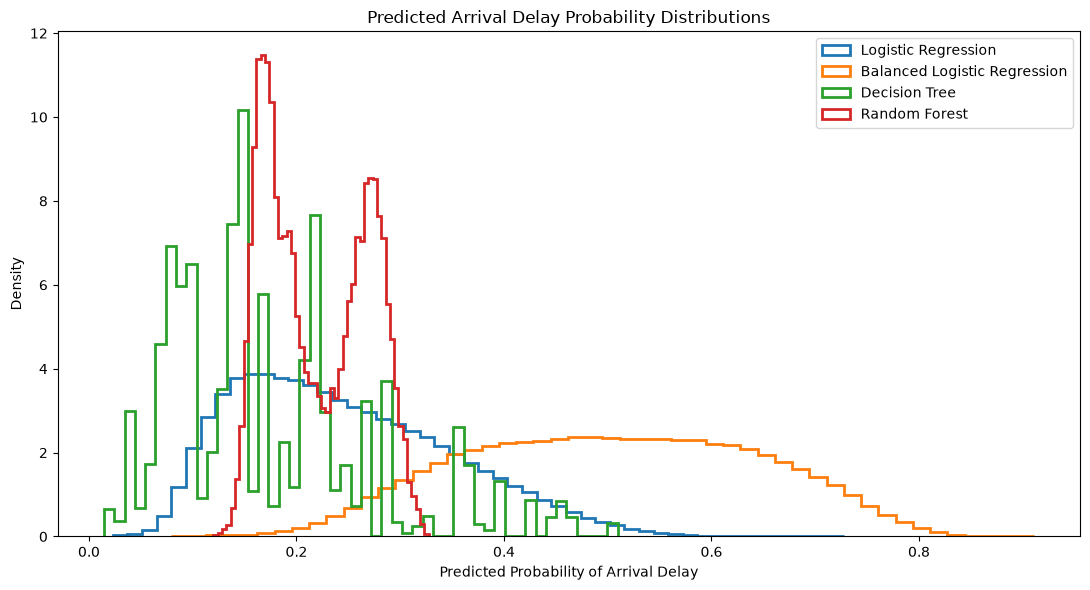

In [94]:
# ==========================================
# Predicted Probability Distribution
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

for model_name, probabilities in models_probabilities.items():

    ax.hist(
        probabilities,
        bins=50,
        density=True,
        histtype="step",
        linewidth=2,
        label=model_name
    )

ax.set_title(
    "Predicted Arrival Delay Probability Distributions"
)

ax.set_xlabel(
    "Predicted Probability of Arrival Delay"
)

ax.set_ylabel("Density")

ax.legend()

plt.tight_layout()

plt.savefig(
    figures_path /
    "11_predicted_probability_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Examine Feature Importance

In [95]:
# ==========================================
# Random Forest Feature Importance
# ==========================================

rf_classifier = (
    random_forest_model.named_steps["classifier"]
)

rf_preprocessor = (
    random_forest_model.named_steps["preprocessor"]
)

# Retrieve transformed feature names

feature_names = (
    rf_preprocessor.get_feature_names_out()
)

# Retrieve feature importance values

importance_values = (
    rf_classifier.feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(
    importance_df.head(20)
)

,Feature,Importance
4,numerical__ARR_HOUR,0.324902
3,numerical__DEP_HOUR,0.282283
1,numerical__FLIGHT_MONTH,0.076452
2,numerical__FLIGHT_WEEKDAY,0.026267
5,categorical__OP_UNIQUE_CARRIER_AA,0.025850
108,categorical__ORIGIN_DEN,0.025596
109,categorical__ORIGIN_DFW,0.020842
0,numerical__DISTANCE,0.016470
14,categorical__OP_UNIQUE_CARRIER_OH,0.015206
9,categorical__OP_UNIQUE_CARRIER_F9,0.012117


## Model Interpretation: Permutation Feature Importance

This analysis evaluates the contribution of each original predictor
by measuring changes in model performance when the values of
individual features are randomly shuffled.

Permutation importance is calculated using a representative sample
from the validation dataset.

In [96]:
# ==========================================
# Permutation Feature Importance
# ==========================================

from sklearn.inspection import permutation_importance

# Use a reproducible validation sample
sample_n = min(20000, len(X_val))

sample_indices = (
    X_val.sample(
        n=sample_n,
        random_state=42
    ).index
)

X_val_sample = X_val.loc[sample_indices]
y_val_sample = y_val.loc[sample_indices]

# Evaluate the selected candidate model
permutation_results = permutation_importance(
    logistic_model,
    X_val_sample,
    y_val_sample,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "Feature": X_val_sample.columns,
    "Importance": permutation_results.importances_mean,
    "Std": permutation_results.importances_std
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance,Std
6,DEP_HOUR,0.0690,0.0029
2,DEST,0.0186,0.0033
1,ORIGIN,0.0157,0.0022
7,ARR_HOUR,0.0100,0.0013
0,OP_UNIQUE_CARRIER,0.0091,0.0010
5,FLIGHT_WEEKDAY,0.0040,0.0006
4,FLIGHT_MONTH,0.0003,0.0001
3,DISTANCE,0.0000,0.0000


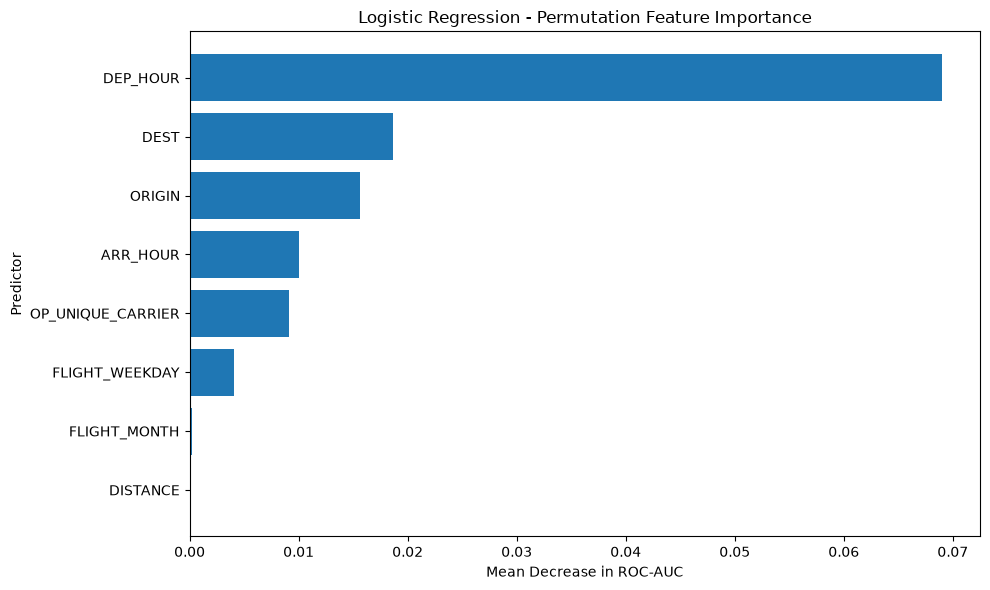

In [97]:
# ==========================================
# Feature Importance Visualization
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

ax.invert_yaxis()

ax.set_title(
    "Logistic Regression - Permutation Feature Importance"
)

ax.set_xlabel(
    "Mean Decrease in ROC-AUC"
)

ax.set_ylabel("Predictor")

plt.tight_layout()

plt.savefig(
    figures_path /
    "12_permutation_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Logistic Regression Brier Score: 0.1591


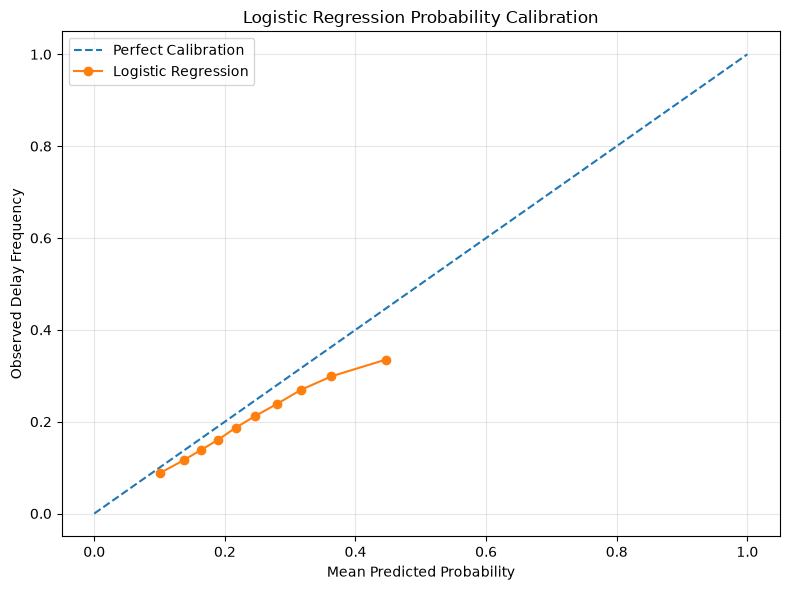

In [98]:
# ==========================================
# Probability Calibration Analysis
# ==========================================

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

prob_true, prob_pred = calibration_curve(
    y_val,
    logistic_probabilities,
    n_bins=10,
    strategy="quantile"
)

brier_score = brier_score_loss(
    y_val,
    logistic_probabilities
)

print(
    "Logistic Regression Brier Score:",
    round(brier_score, 4)
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

ax.set_title(
    "Logistic Regression Probability Calibration"
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Delay Frequency")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_path /
    "13_logistic_regression_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [99]:
# ==========================================
# Final Model Selection
# ==========================================

selected_model_name = "Logistic Regression"

selected_threshold = 0.225

print("Selected Model:", selected_model_name)

print(
    "Selected Classification Threshold:",
    selected_threshold
)

Selected Model: Logistic Regression
Selected Classification Threshold: 0.225


In [100]:
# ==========================================
# Prepare Final Training Data
# ==========================================

X_train_final = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

print(
    "Final training records:",
    len(X_train_final)
)

print(
    "Reserved testing records:",
    len(X_test)
)

Final training records: 6307559
Reserved testing records: 571924


In [101]:
# ==========================================
# Retrain Selected Model
# ==========================================

from sklearn.base import clone

# Create a reproducible sample
final_sample_size = min(
    500000,
    len(X_train_final)
)

final_indices, _ = train_test_split(
    np.arange(len(X_train_final)),
    train_size=final_sample_size,
    stratify=y_train_final,
    random_state=42
)

X_final_sample = X_train_final.iloc[
    final_indices
].copy()

y_final_sample = y_train_final.iloc[
    final_indices
].copy()

# Clone selected model
final_model = clone(logistic_model)

# Train final model
final_model.fit(
    X_final_sample,
    y_final_sample
)

print("Final model training completed.")
print("Training sample:", len(X_final_sample))

Final model training completed.
Training sample: 500000


## Final Model Evaluation — December 2025

The selected Logistic Regression model is evaluated using
the reserved December 2025 testing dataset.

The classification threshold of 0.225 was selected using
the October–November validation dataset.

The testing dataset was not used during model development,
hyperparameter selection, or threshold optimization.

In [102]:
# ==========================================
# Final Test Predictions
# ==========================================

# Generate predicted probabilities
final_test_probabilities = (
    final_model.predict_proba(X_test)[:, 1]
)

# Apply previously selected threshold
final_test_predictions = (
    final_test_probabilities >= selected_threshold
).astype(int)

print("Final test predictions completed.")

print("Testing records:", len(X_test))

print(
    "Predicted delayed flights:",
    final_test_predictions.sum()
)

print(
    "Predicted non-delayed flights:",
    (final_test_predictions == 0).sum()
)

Final test predictions completed.
Testing records: 571924
Predicted delayed flights: 248549
Predicted non-delayed flights: 323375


In [103]:
# ==========================================
# Final Test Performance Metrics
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

final_test_results = {
    "Model": "Final Logistic Regression",

    "Threshold": selected_threshold,

    "Accuracy": accuracy_score(
        y_test,
        final_test_predictions
    ),

    "Precision": precision_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test,
        final_test_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        final_test_probabilities
    ),

    "Average Precision": average_precision_score(
        y_test,
        final_test_probabilities
    ),

    "Brier Score": brier_score_loss(
        y_test,
        final_test_probabilities
    )
}

final_results_df = pd.DataFrame(
    [final_test_results]
)

display(
    final_results_df.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision,Brier Score
0,Final Logistic Regression,0.225,0.5961,0.3433,0.5572,0.4248,0.6166,0.3536,0.1923


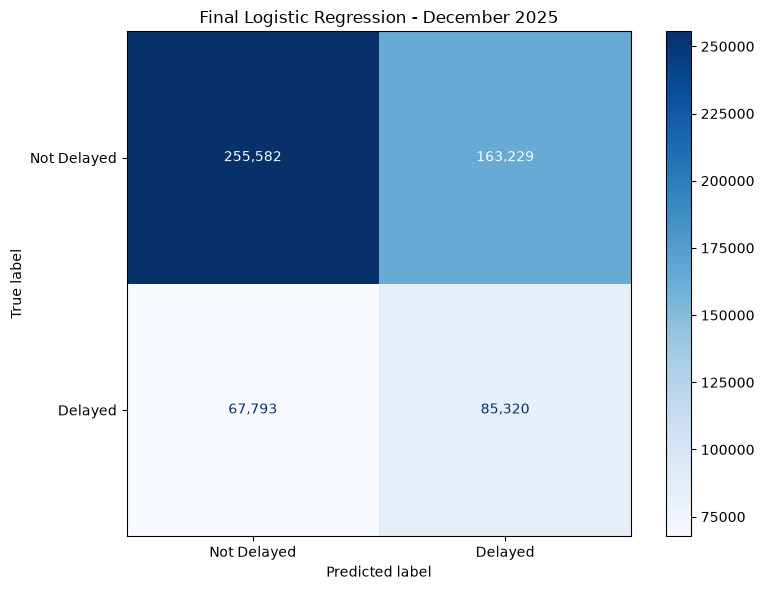

In [104]:
# ==========================================
# Final Test Confusion Matrix
# ==========================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

final_cm = confusion_matrix(
    y_test,
    final_test_predictions
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=[
        "Not Delayed",
        "Delayed"
    ]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format=",d"
)

ax.set_title(
    "Final Logistic Regression - December 2025"
)

plt.tight_layout()

plt.savefig(
    figures_path /
    "14_final_logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
# ==========================================
# Validation vs. Final Test Performance
# ==========================================

validation_row = optimized_comparison[
    optimized_comparison["Model"]
    == "Logistic Regression"
].iloc[0]

validation_results = {
    "Dataset": "Validation (Oct-Nov)",

    "Accuracy": validation_row["Accuracy"],

    "Precision": validation_row["Precision"],

    "Recall": validation_row["Recall"],

    "F1-Score": validation_row["F1-Score"],

    "ROC-AUC": validation_row["ROC-AUC"],

    "Average Precision":
        validation_row["Average Precision"]
}

test_results = {
    "Dataset": "Test (December)",

    "Accuracy": final_test_results["Accuracy"],

    "Precision": final_test_results["Precision"],

    "Recall": final_test_results["Recall"],

    "F1-Score": final_test_results["F1-Score"],

    "ROC-AUC": final_test_results["ROC-AUC"],

    "Average Precision":
        final_test_results["Average Precision"]
}

validation_test_comparison = pd.DataFrame([
    validation_results,
    test_results
])

display(
    validation_test_comparison.round(4)
)

,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Validation (Oct-Nov),0.5546,0.2679,0.6807,0.3845,0.6371,0.2907
1,Test (December),0.5961,0.3433,0.5572,0.4248,0.6166,0.3536


In [106]:
# ==========================================
# Save Final Evaluation Results
# ==========================================

results_path = (
    project_root /
    "reports" /
    "model_results"
)

results_path.mkdir(
    parents=True,
    exist_ok=True
)

# Save final test metrics
final_results_df.to_csv(
    results_path /
    "final_logistic_regression_test_results.csv",
    index=False
)

# Save validation vs test comparison
validation_test_comparison.to_csv(
    results_path /
    "validation_vs_test_comparison.csv",
    index=False
)

print("Final evaluation results saved successfully.")

Final evaluation results saved successfully.


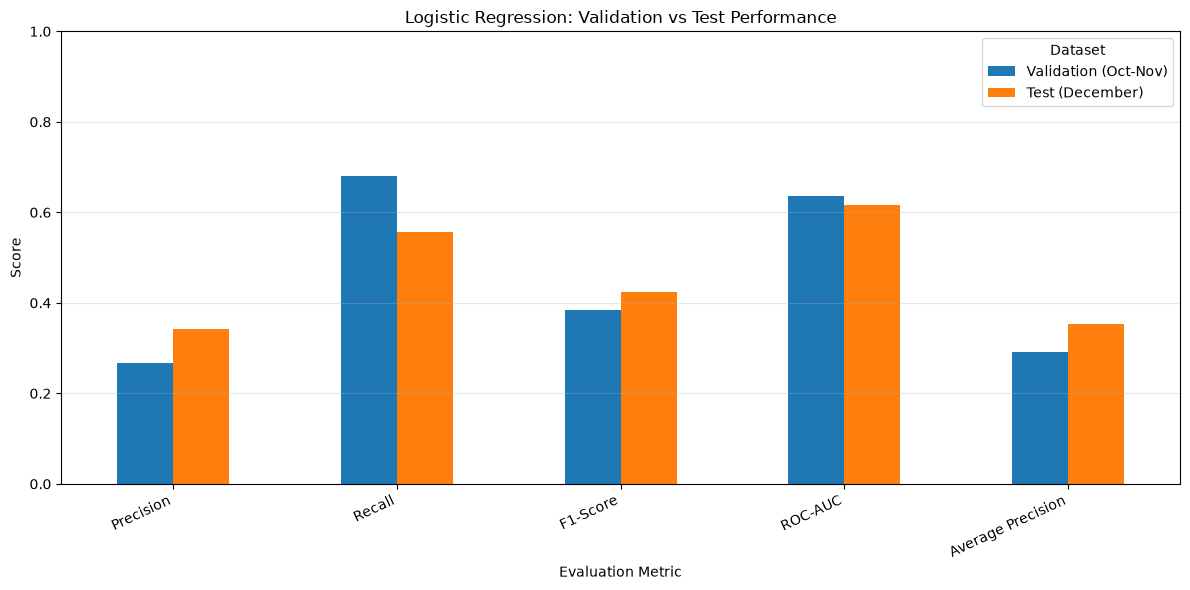

In [107]:
# ==========================================
# Validation vs Test Visualization
# ==========================================

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "Average Precision"
]

comparison_plot = (
    validation_test_comparison
    .set_index("Dataset")[metrics_to_plot]
    .T
)

ax = comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Logistic Regression: Validation vs Test Performance"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")

ax.set_ylim(0, 1)

plt.xticks(rotation=25, ha="right")
plt.legend(title="Dataset")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    figures_path /
    "15_validation_vs_test_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [108]:
# ==========================================
# Save Final Trained Model
# ==========================================

import joblib

models_path = (
    project_root /
    "models"
)

models_path.mkdir(
    parents=True,
    exist_ok=True
)

model_file = (
    models_path /
    "final_logistic_regression_2025.joblib"
)

joblib.dump(
    final_model,
    model_file
)

print("Final model saved successfully.")
print(model_file)

Final model saved successfully.
C:\Repo\airline-flights\models\final_logistic_regression_2025.joblib


In [109]:
# ==========================================
# Save Model Configuration
# ==========================================

import json

model_config = {
    "project": "Predictive Analytics for Airline Flight Delays",

    "model": "Logistic Regression",

    "classification_threshold": selected_threshold,

    "training_period": "January-November 2025",

    "testing_period": "December 2025",

    "training_sample_size": len(X_final_sample),

    "target": "ARR_DEL15_TARGET",

    "features": feature_columns
}

config_file = (
    models_path /
    "final_model_config.json"
)

with open(
    config_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_config,
        file,
        indent=4
    )

print("Model configuration saved.")

Model configuration saved.


## Final Model Reproducibility Verification

This step verifies that the saved Logistic Regression model
can be reloaded successfully and produces predictions
consistent with the original fitted model.

In [110]:
# ==========================================
# Verify Saved Model
# ==========================================

import joblib
import json
import numpy as np

# Load saved model
loaded_model = joblib.load(model_file)

# Load saved configuration
with open(
    config_file,
    "r",
    encoding="utf-8"
) as file:
    loaded_config = json.load(file)

# Verify classification threshold
loaded_threshold = loaded_config[
    "classification_threshold"
]

assert np.isclose(
    loaded_threshold,
    selected_threshold
)

# Select a small test sample
verification_sample = X_test.head(100)

# Predictions from original model
original_probabilities = final_model.predict_proba(
    verification_sample
)[:, 1]

# Predictions from reloaded model
loaded_probabilities = loaded_model.predict_proba(
    verification_sample
)[:, 1]

# Verify identical probabilities
np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities
)

# Verify classification results
original_predictions = (
    original_probabilities >= selected_threshold
).astype(int)

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Saved model verification successful.")
print("Saved threshold:", loaded_threshold)
print("Records verified:", len(verification_sample))

Saved model verification successful.
Saved threshold: 0.225
Records verified: 100
